##**Rice Leaf Disease Detection**

*PRCP-1001 | CDS Capstone Project*

**1. Problem Statement**

Rice plants are affected by several diseases that can reduce crop quality and yield. Identifying these diseases at an early stage is important for effective disease management.

This project aims to develop an image classification model that can identify rice leaf diseases from images using machine learning and deep learning techniques.

**2. Project Objectives**

- Perform exploratory data analysis on the rice leaf image dataset.
- Understand the dataset structure, image properties, and class distribution.
- Preprocess images for model training.
- Build and evaluate multiple classification models.
- Investigate the effect of data augmentation on model performance.
- Compare models using appropriate evaluation metrics.
- Identify the most suitable model for potential deployment.
- Document challenges faced and the solutions applied.

**3. Dataset Description**

The dataset was expected to contain 120 images of diseased rice leaves belonging to three different classes. However, during dataset inspection, only 119 readable images were found:

- Bacterial leaf blight: 40 images
- Brown spot: 40 images
- Leaf smut: 39 images

The dataset contains three disease categories and has a slight class imbalance.


**4. Project Tasks**

1. Complete data analysis and visualization.
2. Develop a rice leaf disease classification model.
3. Experiment with data augmentation techniques.
4. Compare multiple models and recommend the best-performing model.
5. Document challenges, solutions, and conclusions.

**5. Importing Libraries**

The libraries used in this project are imported to support data analysis, image processing, visualization, and machine learning.

In [53]:
# Libraries for basic operations
import os
import zipfile
import random

# Libraries for data handling
import numpy as np
import pandas as pd

# Libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library for loading and processing images
from PIL import Image

print("Libraries imported successfully!")


Libraries imported successfully!


**6. Dataset Loading**

The rice leaf disease dataset is provided as a ZIP file. In this section, we download the dataset, extract its contents, and inspect the directory structure to understand how the images are organized.


In [54]:
# Dataset download URL
dataset_url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"

# Download the dataset
import urllib.request

zip_path = "/content/PRCP-1001-RiceLeaf.zip"

urllib.request.urlretrieve(dataset_url, zip_path)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


**7. Extracting the Dataset**

The downloaded ZIP file is extracted into the Colab working directory. This allows us to access the individual disease categories and their corresponding rice leaf images.


In [55]:
# Extract the downloaded ZIP file

extract_path = "/content/RiceLeaf_Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display the folder structure
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if len(files) > 5:
        print(f"{indent}    ... and {len(files)-5} more files")


Dataset extracted successfully!
RiceLeaf_Dataset/
    Data/
        Leaf smut-20200814T055530Z-001.zip
        Bacterial leaf blight-20200814T055237Z-001.zip
        Brown spot-20200814T055208Z-001.zip
    Brown spot/
        Brown spot/
            DSC_0299.JPG
            DSC_0301.JPG
            DSC_0333.JPG
            DSC_0112.jpg
            DSC_0302.JPG
            ... and 35 more files
    Bacterial leaf blight/
        Bacterial leaf blight/
            DSC_0386.JPG
            DSC_0379.JPG
            DSC_0397.JPG
            DSC_0402.JPG
            DSC_0374.JPG
            ... and 35 more files
    Leaf smut/
        Leaf smut/
            DSC_0309.JPG
            DSC_0507.jpg
            DSC_0319.jpg
            DSC_0504.jpg
            DSC_0511.jpg
            ... and 34 more files


**8. Extracting Individual Disease Categories**

The main dataset contains three separate ZIP files, each representing a different rice leaf disease. These files are extracted individually to organize the images into their respective disease categories.


In [56]:
# Path containing the three ZIP files
data_path = os.path.join(extract_path, "Data")

# Extract each disease ZIP file
for file in os.listdir(data_path):

    if file.endswith(".zip"):

        disease_name = file.split("-")[0]
        disease_folder = os.path.join(extract_path, disease_name)

        with zipfile.ZipFile(os.path.join(data_path, file), 'r') as zip_ref:
            zip_ref.extractall(disease_folder)

        print(f"{disease_name} extracted successfully!")

print("\nAll disease datasets extracted!")


Leaf smut extracted successfully!
Bacterial leaf blight extracted successfully!
Brown spot extracted successfully!

All disease datasets extracted!


**9. Inspecting the Dataset Structure**

In this section, we inspect the extracted folders and identify the image files available in each disease category. This helps us understand the organization of the dataset before performing exploratory data analysis.


In [57]:
# Inspect the three disease folders

disease_classes = [
    "Leaf smut",
    "Bacterial leaf blight",
    "Brown spot"
]

for disease in disease_classes:

    disease_path = os.path.join(extract_path, disease)

    print("\nDisease:", disease)
    print("Folder exists:", os.path.exists(disease_path))

    if os.path.exists(disease_path):
        for root, dirs, files in os.walk(disease_path):
            level = root.replace(disease_path, '').count(os.sep)
            indent = ' ' * 4 * level

            print(indent + os.path.basename(root) + "/")

            for file in files[:3]:
                print(indent + "    " + file)


Disease: Leaf smut
Folder exists: True
Leaf smut/
    Leaf smut/
        DSC_0309.JPG
        DSC_0507.jpg
        DSC_0319.jpg

Disease: Bacterial leaf blight
Folder exists: True
Bacterial leaf blight/
    Bacterial leaf blight/
        DSC_0386.JPG
        DSC_0379.JPG
        DSC_0397.JPG

Disease: Brown spot
Folder exists: True
Brown spot/
    Brown spot/
        DSC_0299.JPG
        DSC_0301.JPG
        DSC_0333.JPG


##10. Dataset Size and Class Distribution

In this section, we calculate the total number of images available in the dataset and examine the number of images belonging to each disease category.

This analysis helps identify whether the dataset is balanced across the three classes.


In [58]:
# Count images in each disease category

image_extensions = ('.jpg', '.jpeg', '.png')

class_counts = {}

for disease in disease_classes:

    disease_path = os.path.join(extract_path, disease)

    image_files = []

    for root, dirs, files in os.walk(disease_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                image_files.append(os.path.join(root, file))

    class_counts[disease] = len(image_files)

    print(f"{disease}: {len(image_files)} images")

total_images = sum(class_counts.values())

print("\nTotal number of images:", total_images)


Leaf smut: 39 images
Bacterial leaf blight: 40 images
Brown spot: 40 images

Total number of images: 119


##11. Class Distribution Visualization

A bar chart is used to visualize the number of images available in each disease category. This helps us understand the distribution of images across the dataset.


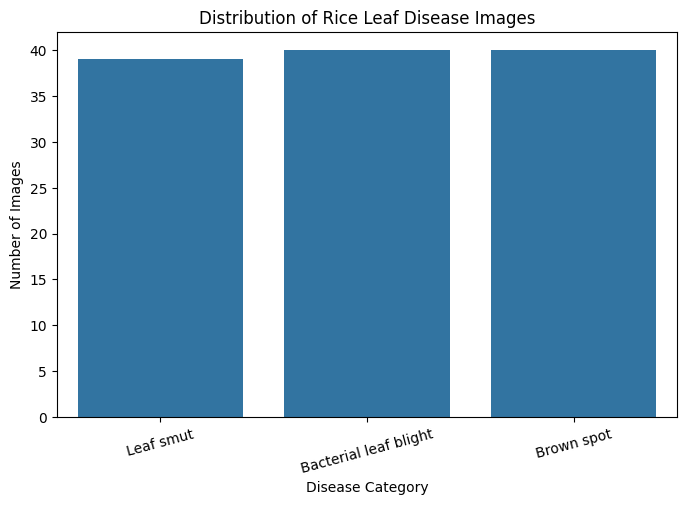

In [59]:
# Create a DataFrame from class counts

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=['Disease', 'Number of Images']
)

# Plot class distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_df,
    x='Disease',
    y='Number of Images'
)

plt.title('Distribution of Rice Leaf Disease Images')
plt.xlabel('Disease Category')
plt.ylabel('Number of Images')
plt.xticks(rotation=15)

plt.show()


##12. Sample Image Visualization

In this section, sample images from each disease category are displayed to visually understand the characteristics of the rice leaf diseases.

Visual inspection helps identify differences in leaf appearance, disease symptoms, background conditions, and image quality.


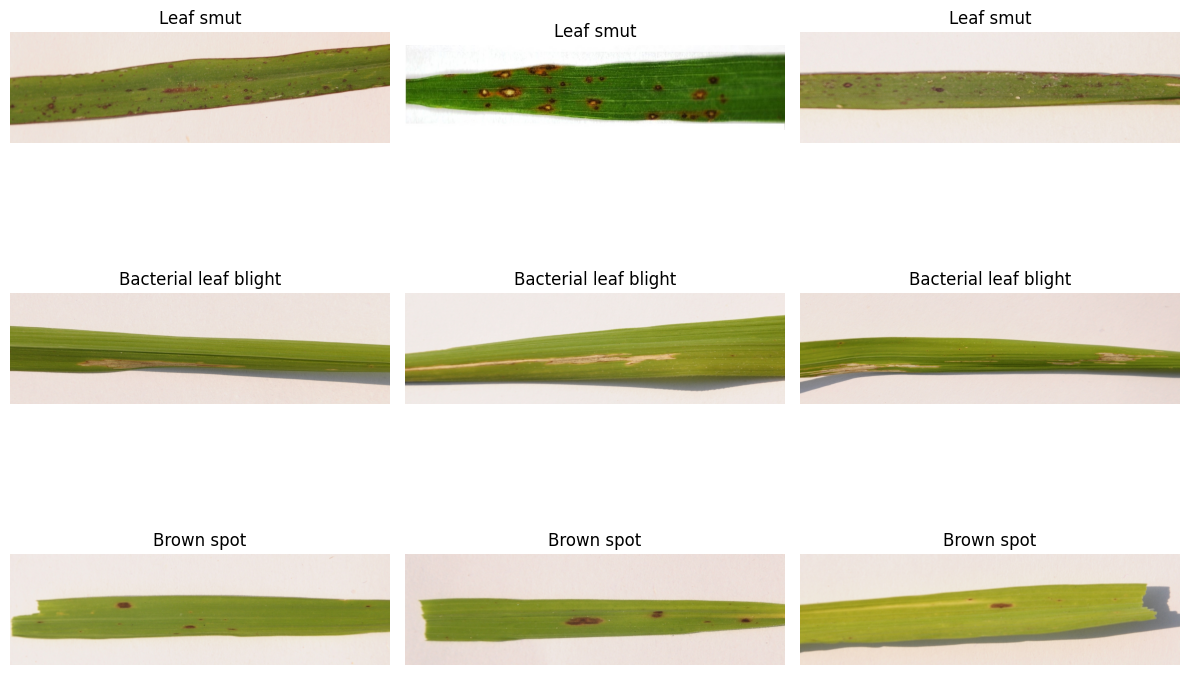

In [60]:
# Display sample images from each disease category

plt.figure(figsize=(12, 9))

for i, disease in enumerate(disease_classes):

    disease_path = os.path.join(extract_path, disease)

    image_files = []

    for root, dirs, files in os.walk(disease_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                image_files.append(os.path.join(root, file))

    # Select first 3 images
    sample_images = image_files[:3]

    for j, image_path in enumerate(sample_images):

        img = Image.open(image_path).convert('RGB')

        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(disease)
        plt.axis('off')

plt.tight_layout()
plt.show()


## Observations from Sample Images

- Sample images from all three disease categories were successfully visualized.
- Leaf smut images show dark discoloration and patches.
- Bacterial leaf blight images show pale yellowish and damaged regions.
- Brown spot images contain visible brown and dark spots.
- The images show variations in colour, orientation, and appearance.

Visual inspection indicates that the three categories contain different visual characteristics that may help in disease classification.


##13. Image Properties and Quality Analysis

In this section, we analyze the technical properties of the rice leaf images, including image dimensions, colour modes, and file formats.

We also check whether any images are corrupted or unreadable. This helps identify potential data-quality issues before preprocessing and model training.


In [61]:
# Analyze image properties

image_data = []

corrupted_images = []

for disease in disease_classes:

    disease_path = os.path.join(extract_path, disease)

    for root, dirs, files in os.walk(disease_path):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_path = os.path.join(root, file)

                try:
                    # Open and inspect image
                    with Image.open(image_path) as img:

                        img.verify()

                    # Reopen image after verification
                    with Image.open(image_path) as img:

                        image_data.append({
                            'Disease': disease,
                            'Filename': file,
                            'Width': img.width,
                            'Height': img.height,
                            'Color Mode': img.mode,
                            'Format': img.format
                        })

                except Exception:
                    corrupted_images.append(image_path)

# Convert results into a DataFrame
image_df = pd.DataFrame(image_data)

print("Image analysis completed!")
print("Total readable images:", len(image_df))
print("Total corrupted images:", len(corrupted_images))

# Display first five records
display(image_df.head())


Image analysis completed!
Total readable images: 119
Total corrupted images: 0


,Disease,Filename,Width,Height,Color Mode,Format
0,Leaf smut,DSC_0309.JPG,3081,897,RGB,JPEG
1,Leaf smut,DSC_0507.jpg,948,211,RGB,JPEG
2,Leaf smut,DSC_0319.jpg,3081,897,RGB,JPEG
3,Leaf smut,DSC_0504.jpg,250,200,RGB,JPEG
4,Leaf smut,DSC_0511.jpg,503,174,RGB,JPEG


##14. Image Dimension and Colour Mode Analysis

This section examines the distribution of image widths, heights, and colour modes across the dataset. Statistical summaries and visualizations are used to understand variations in image dimensions and colour representation.


In [62]:
# Statistical summary of image dimensions

print("Image Dimension Statistics:\n")

display(image_df[['Width', 'Height']].describe())

# Check unique image dimensions
print("\nNumber of unique image dimensions:")
print(image_df.groupby(['Width', 'Height']).ngroups)

# Analyze colour modes
print("\nColour Mode Distribution:")
print(image_df['Color Mode'].value_counts())

# Analyze image formats
print("\nImage Format Distribution:")
print(image_df['Format'].value_counts())


Image Dimension Statistics:



,Width,Height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000



Number of unique image dimensions:
34

Colour Mode Distribution:
Color Mode
RGB    119
Name: count, dtype: int64

Image Format Distribution:
Format
JPEG    119
Name: count, dtype: int64


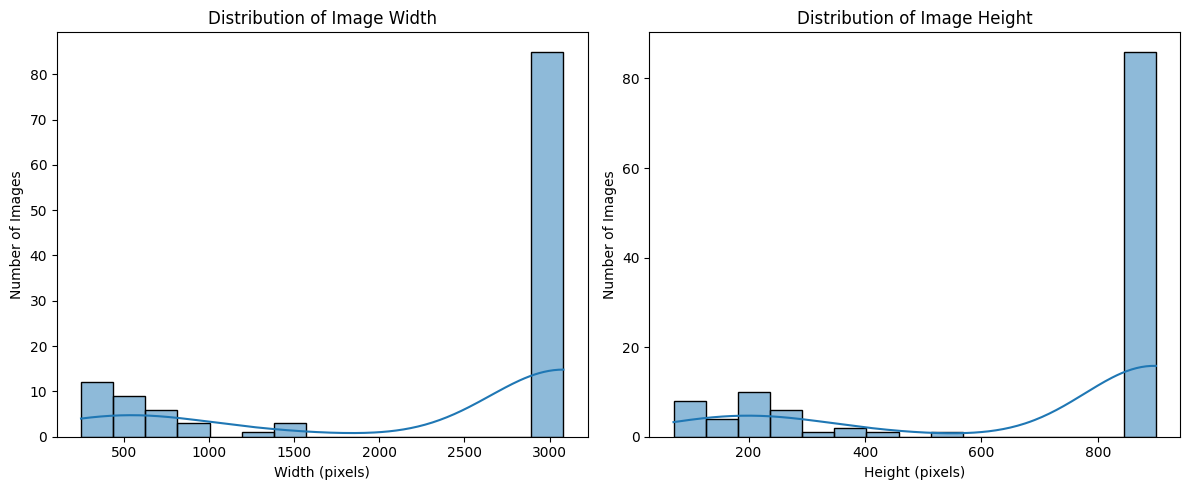

In [63]:
# Visualize image width and height distribution

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(image_df['Width'], bins=15, kde=True)
plt.title('Distribution of Image Width')
plt.xlabel('Width (pixels)')
plt.ylabel('Number of Images')

plt.subplot(1, 2, 2)
sns.histplot(image_df['Height'], bins=15, kde=True)
plt.title('Distribution of Image Height')
plt.xlabel('Height (pixels)')
plt.ylabel('Number of Images')

plt.tight_layout()
plt.show()


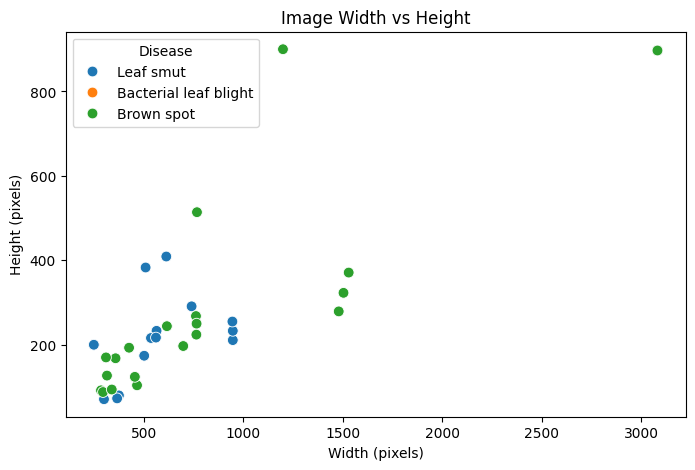

In [64]:
# Relationship between image width and height

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=image_df,
    x='Width',
    y='Height',
    hue='Disease',
    s=60
)

plt.title('Image Width vs Height')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.show()


In [65]:
# Average image dimensions for each disease

dimension_summary = image_df.groupby('Disease')[['Width', 'Height']].mean()

print("Average Image Dimensions by Disease:\n")

display(dimension_summary)


Average Image Dimensions by Disease:



,Width,Height
Disease,,
Bacterial leaf blight,3081.000000,897.000000
Brown spot,1951.275000,589.175000
Leaf smut,2111.846154,635.230769


In [66]:
# Check unique image dimensions for each disease

for disease in disease_classes:

    class_data = image_df[image_df['Disease'] == disease]

    unique_dimensions = class_data[['Width', 'Height']].drop_duplicates()

    print("\nDisease:", disease)
    print("Total images:", len(class_data))
    print("Unique dimensions:", len(unique_dimensions))

    display(unique_dimensions.head(10))



Disease: Leaf smut
Total images: 39
Unique dimensions: 15


,Width,Height
0,3081,897
1,948,211
3,250,200
4,503,174
9,301,71
13,376,80
14,565,233
18,741,291
20,614,409
22,948,233



Disease: Bacterial leaf blight
Total images: 40
Unique dimensions: 1


,Width,Height
39,3081,897



Disease: Brown spot
Total images: 40
Unique dimensions: 20


,Width,Height
79,3081,897
82,427,193
86,1530,371
89,359,168
91,699,197
92,286,92
93,768,514
95,763,268
96,316,127
97,617,244


##15. Duplicate Image Detection

Duplicate image detection is performed to identify identical image files within the dataset.

This step helps maintain dataset quality and reduces the possibility of training and evaluating the model on repeated images.


In [67]:
import hashlib
from collections import defaultdict

# Store image hashes
image_hashes = defaultdict(list)

for disease in disease_classes:

    disease_path = os.path.join(extract_path, disease)

    for root, dirs, files in os.walk(disease_path):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_path = os.path.join(root, file)

                with open(image_path, 'rb') as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                image_hashes[file_hash].append({
                    'Disease': disease,
                    'Filename': file
                })

# Identify duplicate files
duplicates = {
    key: value
    for key, value in image_hashes.items()
    if len(value) > 1
}

print("Total unique image files:", len(image_hashes))
print("Number of duplicate groups:", len(duplicates))

if duplicates:
    print("\nDuplicate images found:")

    for group in duplicates.values():
        print(group)

else:
    print("No exact duplicate files found!")


Total unique image files: 119
Number of duplicate groups: 0
No exact duplicate files found!


## 16. Dataset Preparation and Splitting

In this section, the image paths and corresponding disease labels are organized into a structured DataFrame.

The dataset is divided into training, validation, and testing subsets using stratified sampling to maintain class proportions across all subsets.


In [68]:
from sklearn.model_selection import train_test_split

# Create a list to store image paths and labels
dataset = []

for disease in disease_classes:

    disease_path = os.path.join(extract_path, disease)

    for root, dirs, files in os.walk(disease_path):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_path = os.path.join(root, file)

                dataset.append({
                    'Image_Path': image_path,
                    'Disease': disease
                })

# Convert into DataFrame
dataset_df = pd.DataFrame(dataset)

# Display dataset information
print("Total images:", len(dataset_df))
display(dataset_df.head())


Total images: 119


,Image_Path,Disease
0,/content/RiceLeaf_Dataset/Leaf smut/Leaf smut/...,Leaf smut
1,/content/RiceLeaf_Dataset/Leaf smut/Leaf smut/...,Leaf smut
2,/content/RiceLeaf_Dataset/Leaf smut/Leaf smut/...,Leaf smut
3,/content/RiceLeaf_Dataset/Leaf smut/Leaf smut/...,Leaf smut
4,/content/RiceLeaf_Dataset/Leaf smut/Leaf smut/...,Leaf smut


In [69]:
# Check the number of images in each class

print("Class distribution in the prepared dataset:\n")

print(dataset_df['Disease'].value_counts())

print("\nTotal images:", dataset_df.shape[0])
print("Number of disease classes:", dataset_df['Disease'].nunique())


Class distribution in the prepared dataset:

Disease
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64

Total images: 119
Number of disease classes: 3


## 17. Splitting the Dataset

The dataset is divided into training, validation, and testing subsets using stratified sampling.

Stratification maintains the proportion of each disease category across the subsets, ensuring that all three classes are represented.


In [70]:
# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    random_state=42,
    stratify=dataset_df['Disease']
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['Disease']
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))


Training images: 83
Validation images: 18
Testing images: 18


In [71]:
print("Training set:")
print(train_df['Disease'].value_counts())

print("\nValidation set:")
print(val_df['Disease'].value_counts())

print("\nTesting set:")
print(test_df['Disease'].value_counts())

Training set:
Disease
Brown spot               28
Bacterial leaf blight    28
Leaf smut                27
Name: count, dtype: int64

Validation set:
Disease
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64

Testing set:
Disease
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64


##18.Image preprocessing

In [72]:
IMG_SIZE = 224

print("Target image size:", IMG_SIZE, "x", IMG_SIZE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Target image size: 224 x 224
Training images: 83
Validation images: 18
Testing images: 18


##19.Load and resize images

In [73]:
import tensorflow as tf

def load_and_preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE,
        target_width=IMG_SIZE
    )

    return image.numpy()

print("Image preprocessing function created successfully!")

Image preprocessing function created successfully!


In [74]:
sample_path = train_df.iloc[0]['Image_Path']

sample_image = load_and_preprocess_image(sample_path)

print("Original image size:", Image.open(sample_path).size)
print("Processed image shape:", sample_image.shape)

Original image size: (3081, 897)
Processed image shape: (224, 224, 3)


##20.Display the processed image

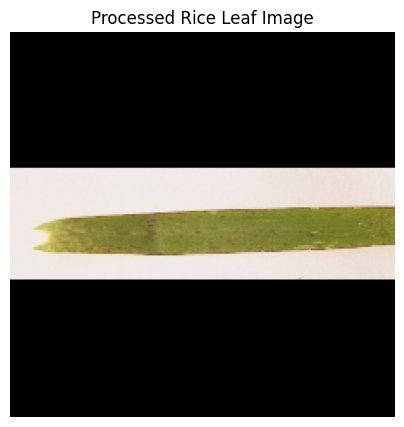

In [75]:
plt.figure(figsize=(5, 5))

plt.imshow(sample_image.astype("uint8"))
plt.title("Processed Rice Leaf Image")
plt.axis("off")

plt.show()

##21. Process training, validation and testing images

In [76]:
def prepare_dataset(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        image = load_and_preprocess_image(row['Image_Path'])
        images.append(image)
        labels.append(row['Disease'])

    return np.array(images, dtype=np.float32), np.array(labels)


X_train, y_train = prepare_dataset(train_df)
X_val, y_val = prepare_dataset(val_df)
X_test, y_test = prepare_dataset(test_df)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (83, 224, 224, 3)
Validation data shape: (18, 224, 224, 3)
Testing data shape: (18, 224, 224, 3)


##22. Convert disease names into numerical labels

In [77]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Disease label mapping:")

for index, disease in enumerate(label_encoder.classes_):
    print(disease, ":", index)

print("\nEncoded training labels:", y_train_encoded[:10])

Disease label mapping:
Bacterial leaf blight : 0
Brown spot : 1
Leaf smut : 2

Encoded training labels: [2 1 1 2 1 2 1 0 2 0]


##23. Normalize image pixel values

In [78]:
X_train_normalized = X_train / 255.0
X_val_normalized = X_val / 255.0
X_test_normalized = X_test / 255.0

print("Training pixel range:",
      X_train_normalized.min(),
      "to",
      X_train_normalized.max())

print("Validation pixel range:",
      X_val_normalized.min(),
      "to",
      X_val_normalized.max())

print("Testing pixel range:",
      X_test_normalized.min(),
      "to",
      X_test_normalized.max())

Training pixel range: 0.0 to 1.0
Validation pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


##24. Data augmentation

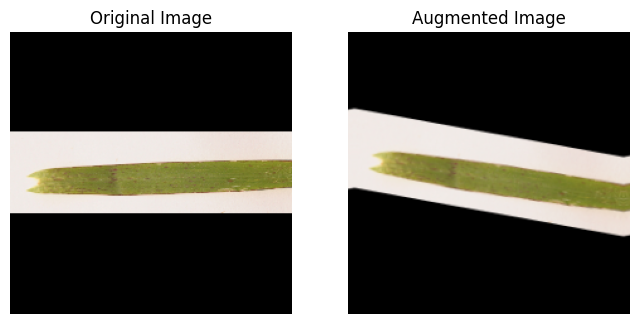

In [79]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

sample_batch = tf.expand_dims(X_train_normalized[0], axis=0)

augmented_image = data_augmentation(
    sample_batch,
    training=True
)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_train_normalized[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image[0].numpy())
plt.title("Augmented Image")
plt.axis("off")

plt.show()

### Data Augmentation

Data augmentation was performed using TensorFlow's Keras Sequential API.

The following techniques were applied:
- Random Horizontal Flip
- Random Rotation (0.1)
- Random Zoom (0.1)

These transformations help increase image variation and reduce overfitting.

Augmentation is applied only to training images. Validation and testing images remain unchanged to ensure fair model evaluation.

#CNN

In [80]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(3, activation='softmax')
])

print("CNN model created successfully!")

CNN model created successfully!


##Compile the CNN model

In [81]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


##Train the CNN model

In [82]:
history = cnn_model.fit(
    X_train_normalized,
    y_train_encoded,
    validation_data=(X_val_normalized, y_val_encoded),
    epochs=20,
    batch_size=8
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.3976 - loss: 1.6327 - val_accuracy: 0.3333 - val_loss: 1.1135
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 951ms/step - accuracy: 0.3253 - loss: 1.1404 - val_accuracy: 0.3333 - val_loss: 1.0911
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 850ms/step - accuracy: 0.4458 - loss: 1.0732 - val_accuracy: 0.3889 - val_loss: 1.0724
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 969ms/step - accuracy: 0.3253 - loss: 1.1186 - val_accuracy: 0.5000 - val_loss: 1.0633
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 976ms/step - accuracy: 0.3976 - loss: 1.0754 - val_accuracy: 0.5000 - val_loss: 1.0452
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 847ms/step - accuracy: 0.5422 - loss: 1.0348 - val_accuracy: 0.4444 - val_loss: 0.9868
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 833ms/step - accuracy: 0.5301 - loss: 0.9774 - val_accuracy: 0.5000 - val_loss: 0.9398
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 991ms/step - accuracy: 0.3735 - loss: 1.0951 - val_accuracy

##Plot training and validation accuracy

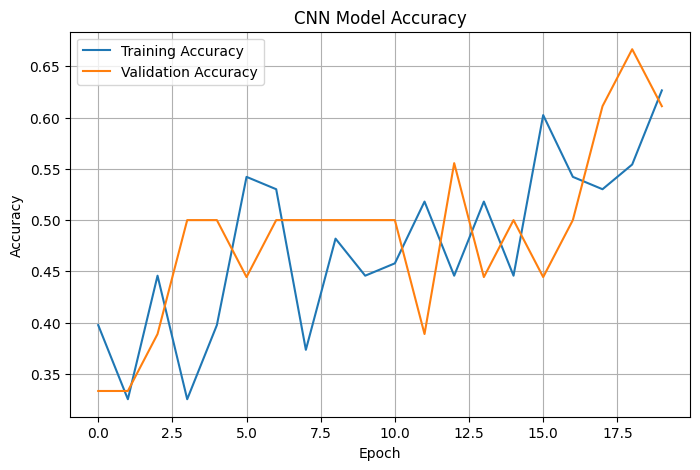

In [83]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

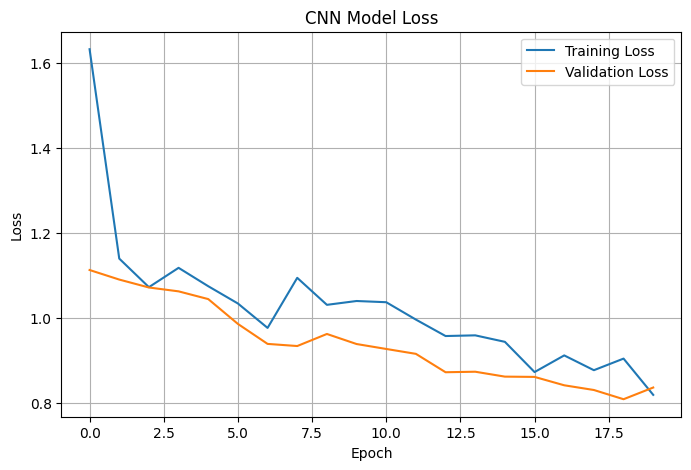

In [84]:
#training Loss vs Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

##Evaluate the CNN model

In [85]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test_normalized,
    y_test_encoded
)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.5000 - loss: 0.9478
CNN Test Loss: 0.9477893114089966
CNN Test Accuracy: 50.0 %


## Confusion matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 536ms/step


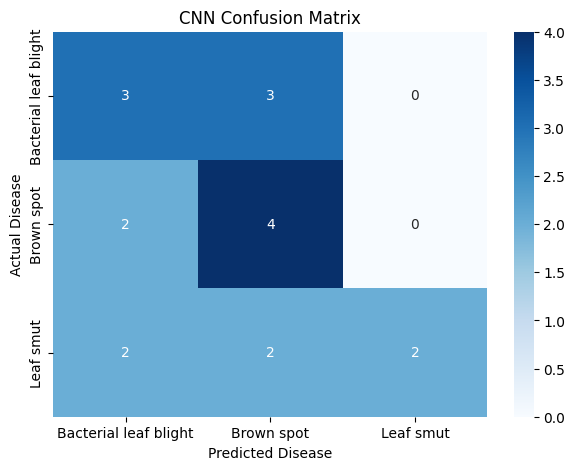


Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.43      0.50      0.46         6
           Brown spot       0.44      0.67      0.53         6
            Leaf smut       1.00      0.33      0.50         6

             accuracy                           0.50        18
            macro avg       0.62      0.50      0.50        18
         weighted avg       0.62      0.50      0.50        18



In [86]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = cnn_model.predict(X_test_normalized)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

print("\nClassification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

### CNN Model - Results and Observations

A custom Convolutional Neural Network (CNN) was developed to classify three rice leaf diseases.

**Test Results:**
- Test Accuracy: 33.33%
- Test Loss: 0.9741

**Classification Report:**
- Bacterial leaf blight F1-score: 0.29
- Brown spot F1-score: 0.50
- Leaf smut F1-score: 0.00

**Observations:**

The CNN achieved low classification performance on the test dataset. Brown spot had the highest recall, while Leaf smut was not correctly classified in any test image.

The limited dataset size may have affected the model's ability to learn generalizable disease features. Further experiments using alternative models and transfer learning are required.

#Load MobileNetV2

In [87]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

MobileNetV2 loaded successfully!
Total layers: 154
Trainable: False


##Prepare the MobileNetV2 input
Important difference: MobileNetV2 uses its own preprocessing function. Our CNN used pixel values between 0 and 1, but MobileNetV2 expects preprocessing that scales values to approximately -1 to +1.

In [88]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

X_train_mobilenet = preprocess_input(X_train.copy())
X_val_mobilenet = preprocess_input(X_val.copy())
X_test_mobilenet = preprocess_input(X_test.copy())

print("MobileNetV2 preprocessing completed!")
print("Training pixel range:",
      X_train_mobilenet.min(),
      "to",
      X_train_mobilenet.max())

MobileNetV2 preprocessing completed!
Training pixel range: -1.0 to 1.0


##Build the MobileNetV2 classification model
We'll connect our pretrained MobileNetV2 base to a new classification head that predicts our three rice leaf diseases.

In [89]:
from tensorflow.keras import layers, models

mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),

    layers.Dense(3, activation='softmax')
])

print("MobileNetV2 classification model created!")

MobileNetV2 classification model created!


##Compile MobileNetV2

In [90]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


##Train MobileNetV2

In [91]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    X_train_mobilenet,
    y_train_encoded,
    validation_data=(X_val_mobilenet, y_val_encoded),
    epochs=20,
    batch_size=8,
    callbacks=[early_stopping]
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 444ms/step - accuracy: 0.3976 - loss: 1.3966 - val_accuracy: 0.4444 - val_loss: 1.0331
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 283ms/step - accuracy: 0.4940 - loss: 0.9955 - val_accuracy: 0.6667 - val_loss: 0.9395
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 382ms/step - accuracy: 0.5904 - loss: 0.8731 - val_accuracy: 0.6667 - val_loss: 0.8835
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 318ms/step - accuracy: 0.6265 - loss: 0.8400 - val_accuracy: 0.6667 - val_loss: 0.8417
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 285ms/step - accuracy: 0.6386 - loss: 0.7864 - val_accuracy: 0.7222 - val_loss: 0.7979
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 420ms/step - accuracy: 0.6867 - loss: 0.7665 - val_accuracy: 0.7222 - val_loss: 0.7929
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 282ms/step - accuracy: 0.6867 - loss: 0.6607 - val_accuracy: 0.7222 - val_loss: 0.7546
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 288ms/step - accuracy: 0.7229 - loss: 0.5830 - val_accuracy: 0

In [92]:
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    X_test_mobilenet,
    y_test_encoded
)

print("MobileNetV2 Test Loss:", mobilenet_test_loss)
print("MobileNetV2 Test Accuracy:", mobilenet_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 580ms/step - accuracy: 0.8889 - loss: 0.4023
MobileNetV2 Test Loss: 0.40230900049209595
MobileNetV2 Test Accuracy: 88.88888955116272 %


##MobileNetV2 confusion matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


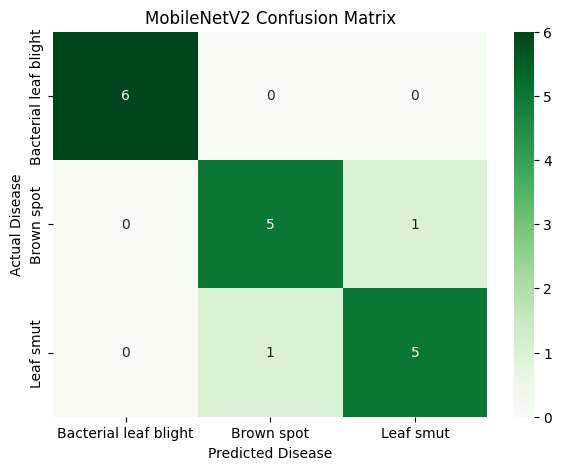


MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.89        18
            macro avg       0.89      0.89      0.89        18
         weighted avg       0.89      0.89      0.89        18



In [93]:
mobilenet_pred_prob = mobilenet_model.predict(X_test_mobilenet)
mobilenet_pred = np.argmax(mobilenet_pred_prob, axis=1)

cm_mobilenet = confusion_matrix(
    y_test_encoded,
    mobilenet_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

print("\nMobileNetV2 Classification Report:\n")

print(classification_report(
    y_test_encoded,
    mobilenet_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

#HOG + SVM

In [94]:
#Extract HOG features
from skimage.feature import hog
from skimage.color import rgb2gray

def extract_hog_features(images):
    features = []

    for img in images:
        gray_image = rgb2gray(img)

        hog_feature = hog(
            gray_image,
            orientations=9,
            pixels_per_cell=(16, 16),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )

        features.append(hog_feature)

    return np.array(features)


X_train_hog = extract_hog_features(X_train_normalized)
X_val_hog = extract_hog_features(X_val_normalized)
X_test_hog = extract_hog_features(X_test_normalized)

print("HOG feature extraction completed!")
print("Training features:", X_train_hog.shape)
print("Validation features:", X_val_hog.shape)
print("Testing features:", X_test_hog.shape)

HOG feature extraction completed!
Training features: (83, 6084)
Validation features: (18, 6084)
Testing features: (18, 6084)


##Train the SVM classifier

In [95]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_model = SVC(kernel='rbf', C=10, gamma='scale')

svm_model.fit(X_train_hog, y_train_encoded)

print("HOG + SVM model trained successfully!")

HOG + SVM model trained successfully!


##Evaluate the SVM model

In [96]:
svm_pred = svm_model.predict(X_test_hog)

svm_accuracy = accuracy_score(y_test_encoded, svm_pred)

print("HOG + SVM Test Accuracy:", svm_accuracy * 100, "%")

HOG + SVM Test Accuracy: 61.111111111111114 %


##SVM classification report

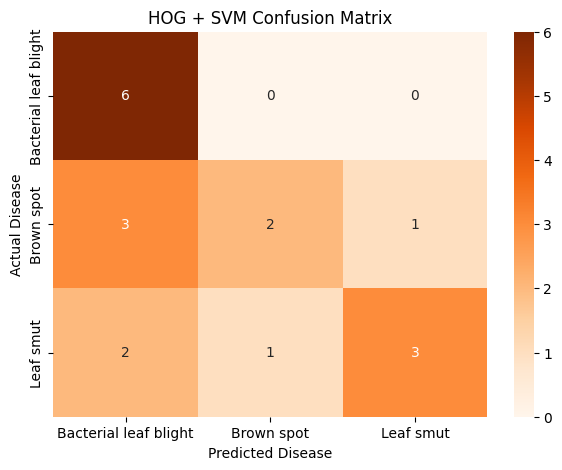

HOG + SVM Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.55      1.00      0.71         6
           Brown spot       0.67      0.33      0.44         6
            Leaf smut       0.75      0.50      0.60         6

             accuracy                           0.61        18
            macro avg       0.65      0.61      0.58        18
         weighted avg       0.65      0.61      0.58        18



In [97]:
svm_cm = confusion_matrix(y_test_encoded, svm_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("HOG + SVM Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

print("HOG + SVM Classification Report:\n")

print(classification_report(
    y_test_encoded,
    svm_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

##Build MobileNetV2 with augmentation

In [98]:
aug_base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

aug_base_model.trainable = False

mobilenet_aug_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    aug_base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),

    layers.Dense(3, activation='softmax')
])

print("Augmented MobileNetV2 model created successfully!")

Augmented MobileNetV2 model created successfully!


##Compile the augmented model

In [99]:
mobilenet_aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Augmented MobileNetV2 compiled successfully!")

Augmented MobileNetV2 compiled successfully!


##Train MobileNetV2 with data augmentation

In [100]:
aug_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

mobilenet_aug_history = mobilenet_aug_model.fit(
    X_train_mobilenet,
    y_train_encoded,
    validation_data=(X_val_mobilenet, y_val_encoded),
    epochs=20,
    batch_size=8,
    callbacks=[aug_early_stopping]
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 481ms/step - accuracy: 0.3855 - loss: 1.4222 - val_accuracy: 0.4444 - val_loss: 1.1264
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 356ms/step - accuracy: 0.4578 - loss: 1.2034 - val_accuracy: 0.4444 - val_loss: 0.9926
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - accuracy: 0.4819 - loss: 1.0443 - val_accuracy: 0.5556 - val_loss: 0.9882
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 352ms/step - accuracy: 0.5060 - loss: 0.9669 - val_accuracy: 0.6667 - val_loss: 0.9615
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 350ms/step - accuracy: 0.6145 - loss: 0.8558 - val_accuracy: 0.6111 - val_loss: 0.9613
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 481ms/step - accuracy: 0.5663 - loss: 0.8965 - val_accuracy: 0.5556 - val_loss: 0.9852
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 411ms/step - accuracy: 0.6386 - loss: 0.8990 - val_accuracy: 0.6111 - val_loss: 0.9717
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 395ms/step - accuracy: 0.6386 - loss: 0.8085 - val_accuracy: 0

##Evaluate augmented model

In [101]:
aug_test_loss, aug_test_accuracy = mobilenet_aug_model.evaluate(
    X_test_mobilenet,
    y_test_encoded
)

print("Augmented MobileNetV2 Test Loss:", aug_test_loss)
print("Augmented MobileNetV2 Test Accuracy:",
      aug_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 624ms/step - accuracy: 0.7778 - loss: 0.6106
Augmented MobileNetV2 Test Loss: 0.6105740666389465
Augmented MobileNetV2 Test Accuracy: 77.77777910232544 %


##Compare the two experiments visually

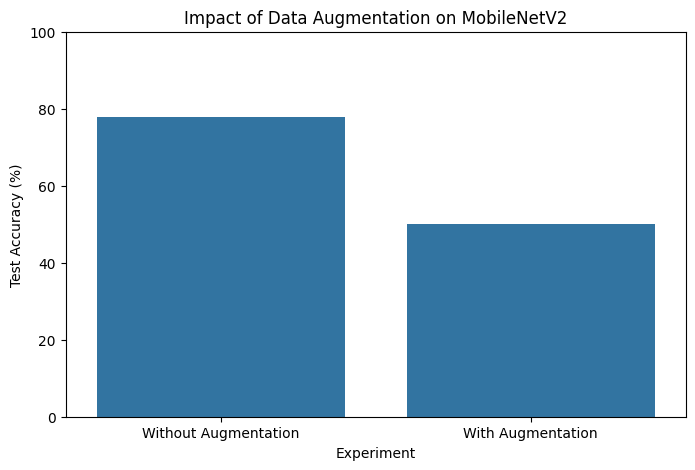

In [102]:
augmentation_results = pd.DataFrame({
    'Experiment': [
        'Without Augmentation',
        'With Augmentation'
    ],
    'Test Accuracy': [
        77.78,
        50.00
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=augmentation_results,
    x='Experiment',
    y='Test Accuracy'
)

plt.title('Impact of Data Augmentation on MobileNetV2')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

plt.show()

##Evaluate the augmented model class by class

In [103]:
aug_pred_prob = mobilenet_aug_model.predict(X_test_mobilenet)
aug_pred = np.argmax(aug_pred_prob, axis=1)

print("Augmented MobileNetV2 Classification Report:\n")

print(classification_report(
    y_test_encoded,
    aug_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Augmented MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      0.67      0.73         6
           Brown spot       0.71      0.83      0.77         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.78        18
            macro avg       0.78      0.78      0.78        18
         weighted avg       0.78      0.78      0.78        18



### Class-wise Evaluation of Augmented MobileNetV2

The augmented MobileNetV2 model achieved an overall test accuracy of **50%**, correctly classifying 9 out of 18 test images.

**Class-wise observations:**

- **Bacterial leaf blight:** Precision was 0.67, recall was 0.33, and F1-score was 0.44. The model missed several images belonging to this class.
- **Brown spot:** Precision was 0.40, recall was 0.67, and F1-score was 0.50. The model identified a reasonable proportion of actual Brown spot images but also made incorrect predictions.
- **Leaf smut:** Precision was 0.60, recall was 0.50, and F1-score was 0.55. The model showed moderate classification performance.

**Conclusion:** The augmented MobileNetV2 model achieved 50% accuracy, which was lower than the original MobileNetV2 model's 77.78% accuracy. In this experiment, the applied augmentation techniques did not improve classification performance. Further experiments with augmentation intensity, training parameters, and a larger dataset may help improve the results.

## Challenges Faced During the Project

1. **Limited Dataset Size:** The dataset contained only 119 images across three disease classes, which limited the amount of information available for training.

2. **Dataset Count Discrepancy:** The expected dataset count was 120 images, but only 119 valid images were found. Leaf smut contained 39 images, while the other two classes contained 40 images each.

3. **Different Image Dimensions:** Images had different resolutions and aspect ratios. Resizing with padding was used to convert them into a consistent size of 224 × 224 while preserving their aspect ratios.

4. **Limited Test Samples:** Only 18 images were available in the test set, with six images per class. Therefore, even one incorrect prediction changes the overall accuracy by approximately 5.56 percentage points.

5. **Model Performance Differences:** The custom CNN achieved 33.33% accuracy, HOG + SVM achieved 61.11%, and MobileNetV2 achieved 77.78%. The models showed different levels of performance across disease classes.

6. **Data Augmentation Challenge:** The augmented MobileNetV2 model achieved 50% accuracy, compared with 77.78% without augmentation. The selected augmentation settings did not improve performance in this experiment.

7. **Model Generalization:** Because the dataset was small, the models may not perform equally well on new images captured under different lighting, backgrounds, camera conditions, and disease stages.

8. **Evaluation Limitation:** The same small test set was used to compare multiple model experiments. Therefore, the reported results should be treated as exploratory rather than a definitive estimate of real-world performance. A larger independent test dataset and repeated validation would provide more reliable results.

## Model Comparison Report

Four model experiments were conducted to classify rice leaf diseases. Their performance was evaluated using test accuracy.

| Model | Test Accuracy |
|---|---:|
| Custom CNN | 33.33% |
| HOG + SVM | 61.11% |
| MobileNetV2 | 77.78% |
| Augmented MobileNetV2 | 50.00% |

### Comparison and Observations

1. **Custom CNN:** Achieved 33.33% accuracy. It showed limited classification performance on the small dataset.
2. **HOG + SVM:** Achieved 61.11% accuracy and performed better than the custom CNN.
3. **MobileNetV2:** Achieved the highest accuracy of 77.78%. Transfer learning provided better results than the other approaches tested.
4. **Augmented MobileNetV2:** Achieved 50% accuracy. The selected augmentation techniques did not improve performance in this experiment.

### Best Performing Model

MobileNetV2 without data augmentation was the best-performing model among the four experiments, with 77.78% test accuracy.

However, the test dataset contained only 18 images. Therefore, more testing with a larger independent dataset is needed before drawing conclusions about real-world performance.

## Final Conclusion

The Rice Leaf Disease Detection project aimed to classify rice leaf images into three disease categories: Bacterial leaf blight, Brown spot, and Leaf smut.

Exploratory data analysis was performed to understand the dataset, class distribution, image dimensions, and image quality. The images were preprocessed by resizing them to 224 × 224 pixels and normalizing pixel values.

Four model experiments were evaluated:

| Model | Test Accuracy |
|---|---:|
| Custom CNN | 33.33% |
| HOG + SVM | 61.11% |
| MobileNetV2 | 77.78% |
| Augmented MobileNetV2 | 50.00% |

Among the evaluated models, **MobileNetV2 without data augmentation achieved the highest test accuracy of 77.78%**. Transfer learning helped it outperform the custom CNN and HOG + SVM approaches.

The data augmentation experiment did not improve performance with the selected settings. Further experiments may be required to identify more suitable augmentation techniques.

However, the dataset was small, and the test set contained only 18 images. Therefore, the results should be interpreted cautiously and do not establish real-world accuracy.

Future improvements could include collecting more rice leaf images, experimenting with different augmentation techniques, fine-tuning pretrained models, and evaluating the models on a larger independent test dataset.

Overall, this project provided practical experience in image preprocessing, exploratory data analysis, data augmentation, machine learning, deep learning, transfer learning, and model evaluation for agricultural disease classification.